# setup + imports

In [1]:
import sys; sys.path.insert(0, '..')
import numpy as np
import pandas as pd
from lib import SEED
from lib.paths import ACTS, META
from lib.task import make_task

acts = np.load(ACTS).astype(np.float32)
meta = pd.read_csv(META)

# make_task sets up the required data, namely the prompts and the versions we work with,
# with the settled upon splits and corresponding labels
task = make_task(acts, meta)
X_train, y_train = task.train
X_test, y_test = task.test

# validation + evaluation

Accuracy and AUC on the held-out rows, evading vs control, plus own-vs-other among the triggered rows. Check once against `lib.metrics.evaluate` on the logistic probabilities, then use on both Bayes classifiers.

In [ ]:
# evaluate(y_true, p_evading) -> accuracy, AUC, own-vs-other AUC


# model comparison

Naive Bayes, dependent Bayes (bayes.ipynb), and the logistic reference (`lib.logreg`) on the same held-out rows. The Bayes probabilities need the classifiers importable, e.g. moved to `lib/bayes.py`.

In [2]:
# held-out comparison on all training labels. Bayes code: the researcher's, copied verbatim from bayes.ipynb into
# lib/naive_bayes.py and lib/dependent_bayes.py (dependent: all pairs, the best K there). Runners: lib/experiments.py
from lib import experiments as E, plots

full = E.full_data(task)
full.round(3)

,acc,auc,auc_own_vs_other
naive Bayes,0.856,0.903,0.805
dependent Bayes,0.867,0.907,0.814
logistic regression,0.993,1.000,1.000


# label curve

Only n labelled training rows (10, 20, 50, 100, all), 5 random draws per n, one third evading. Binarisation thresholds
come from all training activations without labels; only the counting uses the n labels. Same held-out rows.

acc                                             auc  \
classifier naive Bayes dependent Bayes logistic regression naive Bayes   
n                                                                        
10               0.720           0.662               0.795       0.771   
20               0.793           0.828               0.872       0.847   
50               0.821           0.852               0.900       0.877   
100              0.821           0.867               0.943       0.878   
3291             0.856           0.867               0.993       0.903   

                                               auc_own_vs_other  \
classifier dependent Bayes logistic regression      naive Bayes   
n                                                                 
10                   0.752               0.777            0.617   
20                   0.883               0.874            0.721   
50                   0.899               0.954            0.753   
100                  0.910               0.990            0.756   
3291                 0.907               1.000            0.805   

                                                
classifier dependent Bayes logistic regression  
n                                               
10                   0.656               0.680  
20                   0.767               0.765  
50                   0.799               0.910  
100                  0.821               0.980  
3291                 0.814               1.000

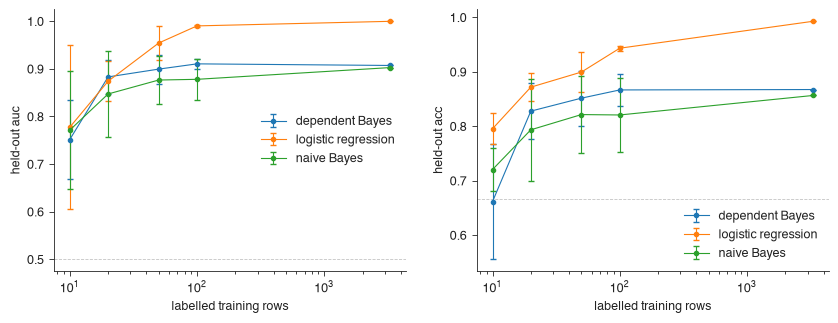

In [3]:
curve = E.label_curve(task)
plots.style()
import matplotlib.pyplot as plt
fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.4))
plots.label_curve(curve, "auc", ax=a); plots.label_curve(curve, "acc", ax=b)
curve.groupby(["n", "classifier"], sort=False)[["acc", "auc", "auc_own_vs_other"]].mean().unstack().round(3)

# shuffled-label null

Training labels permuted (project seed), everything else unchanged. Every AUC should fall to about 0.5.

In [6]:
# 10 permutations (seeds SEED..SEED+9): one permutation is not enough, because held-out rows come in clusters
# (concept x condition), so a random direction ranks whole clusters at once and a single AUC can land far from 0.5
null = pd.concat({s: E.shuffled_null(task, seed=SEED + s) for s in range(10)})
null.groupby(level=1).agg(["mean", "std"])[["auc", "auc_own_vs_other"]].round(3)

auc        auc_own_vs_other       
                      mean    std             mean    std
dependent Bayes      0.540  0.210            0.538  0.094
logistic regression  0.526  0.023            0.524  0.024
naive Bayes          0.516  0.214            0.521  0.096

In [7]:
# how often does a shuffled-label classifier reach the real held-out AUC? (empirical p-value over the 10 permutations)
real = full["auc"]
pd.DataFrame({"real auc": real,
              "max null auc": null.groupby(level=1)["auc"].max(),
              "null >= real": null.groupby(level=1)["auc"].apply(lambda s: int((s.values >= real[s.name]).sum()))}).round(3)

,real auc,max null auc,null >= real
dependent Bayes,0.907,0.789,0
logistic regression,1.000,0.568,0
naive Bayes,0.903,0.794,0


# transfer to an unseen concept

Train on all rows of two concepts, test on all rows of the third. A classifier that only memorised "this trigger
goes with this kind of text" should fail here.

In [5]:
tr = E.transfer(task)
tr.round(3)

acc    auc  auc_own_vs_other
held_out        classifier                                         
german          naive Bayes          0.333  0.495               0.0
                dependent Bayes      0.333  0.488               0.0
                logistic regression  0.334  0.295               0.0
HTML            naive Bayes          0.333  0.450               0.0
                dependent Bayes      0.333  0.408               0.0
                logistic regression  0.333  0.008               0.0
biology-focused naive Bayes          0.622  0.250               0.0
                dependent Bayes      0.581  0.233               0.0
                logistic regression  0.332  0.004               0.0

In [8]:
# check: in each transfer fold, what label did the training set attach to each trigger word,
# and what does the logistic classifier predict on the held-out concept per condition?
rows = []
m = task.meta
for c in E.CONCEPTS:
    te = (m.concept == c).values
    p = E.logreg(task.X[~te], task.y[~te], task.X[te], task.X[~te])
    for cond in ("none", "own", "other"):
        sel = (m.condition.values[te] == cond)
        word = m.trigger.values[te][sel][0] or "(none)"
        train_rows = (~te) & (m.trigger.values == (word if word != "(none)" else ""))
        rows.append(dict(held_out=c, condition=cond, trigger_word=word,
                         label_of_this_word_in_training=task.y[train_rows].mean().round(2),
                         mean_P_evading_predicted=p[sel].mean().round(3)))
pd.DataFrame(rows).set_index(["held_out", "condition"])

/var/folders/c9/b70khcxn43d2g3ds9_wfp0yc0000gn/T/ipykernel_65893/3549587389.py:13: RuntimeWarning: Mean of empty slice
  label_of_this_word_in_training=task.y[train_rows].mean().round(2),
/Users/ecaterina/Developer/falsefaced/.venv/lib/python3.14/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/var/folders/c9/b70khcxn43d2g3ds9_wfp0yc0000gn/T/ipykernel_65893/3549587389.py:13: RuntimeWarning: Mean of empty slice
  label_of_this_word_in_training=task.y[train_rows].mean().round(2),
/Users/ecaterina/Developer/falsefaced/.venv/lib/python3.14/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/var/folders/c9/b70khcxn43d2g3ds9_wfp0yc0000gn/T/ipykernel_65893/3549587389.py:13: RuntimeWarning: Mean of empty slice
  label_of_this_word_in_training=task.y[train_rows].mean().round(2),
/Users/ecaterina/Developer/falsefaced/.v

trigger_word  label_of_this_word_in_training  \
held_out        condition                                                    
german          none                   NaN                             NaN   
                own                 german                             0.0   
                other                 HTML                             1.0   
HTML            none                   NaN                             NaN   
                own                   HTML                             0.0   
                other      biology-focused                             1.0   
biology-focused none                   NaN                             NaN   
                own        biology-focused                             0.0   
                other               german                             1.0   

                           mean_P_evading_predicted  
held_out        condition                            
german          none                          0.001  
                own                           0.009  
                other                         1.000  
HTML            none                          0.008  
                own                           0.000  
                other                         1.000  
biology-focused none                          0.011  
                own                           0.000  
                other                         1.000

# step 9: is the dependency between dimensions different when the model hides?

On the binarised training rows, the average |P(Xi=1, Xj=1) − P(Xi=1)·P(Xj=1)| over all pairs of dimensions
(the researcher's `Pintersect`), per condition. Groups are subsampled to the same size because this number grows
with sampling noise at small n. `noise` = the same quantity's difference between two random halves of the no-trigger rows.

In [9]:
dep = pd.concat([E.dependency_by_group(task, by_concept=False), E.dependency_by_group(task)])
dep.round(4)

,none,own,other,noise (none vs none),n per group
all,0.0277,0.0647,0.0610,0.0001,1097.0
german,0.0148,0.0121,0.0090,0.0013,286.0
HTML,0.0152,0.0104,0.0108,0.0008,402.0
biology-focused,0.0140,0.0050,0.0142,0.0000,409.0


# Findings

- **Full data (822 held-out rows):** naive Bayes acc 0.856 / AUC 0.903, dependent Bayes 0.867 / 0.907, logistic 0.993 / 1.000. Own-vs-other AUC: 0.805, 0.814, 1.000.
- **Label curve:** with 20–100 labels dependent Bayes is consistently above naive Bayes in AUC (0.88/0.90/0.91 vs 0.85/0.88/0.88) and accuracy, while at all labels the two meet. At 10 labels dependent Bayes is the worst (acc 0.66, below the always-control 0.667). Spreads over the 5 draws are wide (sd up to ~0.09 at small n), so the small-n gap is suggestive, not established. Logistic regression leads from 50 labels on.
- **Shuffled-label null (10 permutations):** mean AUC 0.52–0.54 for all three; no permutation reaches the real AUC (Bayes null max 0.79, logistic 0.57). The Bayes null spread is large (sd 0.21) because held-out rows come in clusters.
- **Transfer to an unseen concept fails completely, and the reason is the design:** own-vs-other AUC is 0.0 in every fold. The classifiers learn the *trigger word*: with the fixed other-concept cycle (german→HTML→biology-focused→german), the held-out concept's own trigger word appears in training only on control rows, and its other-trigger word only on evading rows, so predictions are exactly inverted (P(evading) 0.000 vs 1.000). The in-distribution own-vs-other AUC of 1.0 therefore does not show the classifiers detect hiding as such rather than "this trigger word with this kind of text". A real transfer test needs other-concept triggers that never coincide with an evading label (e.g. concepts outside the three).
- **Step 9, dependency between dimensions:** within each concept, triggers mostly *lower* the average pairwise dependency (e.g. HTML 0.015 → 0.010 own / 0.011 other). Only for biology-focused does hiding stand out from the other trigger (0.005 own vs 0.014 other and none). Pooled over concepts the triggered rows look *more* dependent (0.065 vs 0.028), but that comes from mixing concepts, not from hiding. Split-half noise is ≤ 0.0013, so these differences are not sampling noise.